<a href="https://colab.research.google.com/github/zogydinesh/ITA-0616/blob/main/program16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rows: 178  Features: 13  Class counts: {1: 59, 2: 71, 3: 48} 

Train size: 142  Test size: 36 

Comparison of classification algorithms:
                      Accuracy %  Precision  Recall  F1-score  5-fold CV %  CV std
Algorithm                                                                         
Logistic Regression        97.22       0.98    0.97      0.97        98.33    1.36
SVM                        97.22       0.98    0.97      0.97        98.33    2.22
Random Forest             100.00       1.00    1.00      1.00        97.75    2.13
Naive Bayes                97.22       0.97    0.98      0.97        97.19    2.52
K-Nearest Neighbours       97.22       0.97    0.98      0.97        97.17    1.81
Decision Tree              94.44       0.96    0.94      0.95        89.32    3.80

Best algorithm (highest 5-fold CV accuracy, ties go to the more stable one): Logistic Regression

Confusion matrix of Logistic Regression (rows = actual, columns = predicted):
         Class 1  Clas

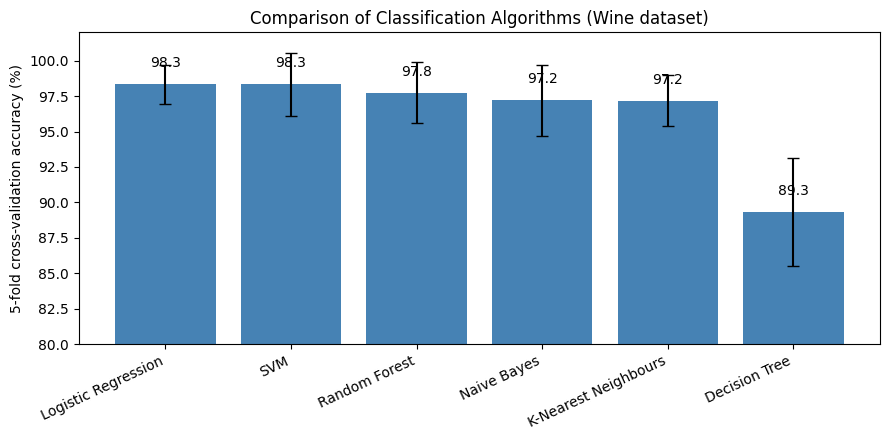

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Dataset: Wine recognition data - UCI Machine Learning Repository (program16.csv, used as it is, no header row)
# 13 chemical measurements of wine, class 1, 2 or 3 = three different grape growers (cultivars)

# ---- 1. Load CSV ----
cols = ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols',
        'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity',
        'hue', 'od280_od315', 'proline', 'class']
df = pd.read_csv('program16.csv', header=None, names=cols)
X = df.drop(columns='class').values
y = df['class'].values
counts = {int(k): int(v) for k, v in pd.Series(y).value_counts().sort_index().items()}
print("Rows:", len(df), " Features:", X.shape[1], " Class counts:", counts, "\n")

# ---- 2. Train / test split (80% / 20%, same classes in both parts) ----
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train size:", len(Xtr), " Test size:", len(Xte), "\n")

# ---- 3. The classification algorithms to compare ----
# (scaling is done inside the pipeline so K-NN, Logistic Regression and SVM work properly)
models = {
    'K-Nearest Neighbours': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'Naive Bayes':          GaussianNB(),
    'Logistic Regression':  make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Decision Tree':        DecisionTreeClassifier(random_state=42),
    'Random Forest':        RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM':                  make_pipeline(StandardScaler(), SVC()),
}

# ---- 4. Train, test and score each model ----
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in models.items():
    start = time.time()
    model.fit(Xtr, ytr)
    train_time = time.time() - start
    pred = model.predict(Xte)
    cv_scores = cross_val_score(model, X, y, cv=cv)           # 5-fold cross validation on all data
    rows.append({
        'Algorithm': name,
        'Accuracy %': accuracy_score(yte, pred) * 100,
        'Precision': precision_score(yte, pred, average='macro'),
        'Recall': recall_score(yte, pred, average='macro'),
        'F1-score': f1_score(yte, pred, average='macro'),
        '5-fold CV %': cv_scores.mean() * 100,
        'CV std': cv_scores.std() * 100,
    })

# ---- 5. Comparison table ----
result = pd.DataFrame(rows).set_index('Algorithm').round(2)
# best = highest 5-fold CV accuracy; if tied, the one with the smaller CV std (more stable)
result = result.sort_values(['5-fold CV %', 'CV std'], ascending=[False, True])
print("Comparison of classification algorithms:")
print(result.to_string())

best = result.index[0]
print(f"\nBest algorithm (highest 5-fold CV accuracy, ties go to the more stable one): {best}")

# ---- 6. Confusion matrix of the best algorithm ----
cm = confusion_matrix(yte, models[best].predict(Xte))
print(f"\nConfusion matrix of {best} (rows = actual, columns = predicted):")
print(pd.DataFrame(cm, index=['Class 1', 'Class 2', 'Class 3'], columns=['Class 1', 'Class 2', 'Class 3']))

# ---- 7. Bar chart ----
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(result.index, result['5-fold CV %'], yerr=result['CV std'], capsize=4, color='steelblue')
ax.set_ylim(80, 102)
ax.set_ylabel('5-fold cross-validation accuracy (%)')
ax.set_title('Comparison of Classification Algorithms (Wine dataset)')
plt.xticks(rotation=25, ha='right')
for i, v in enumerate(result['5-fold CV %']):
    ax.text(i, v + 1.2, f"{v:.1f}", ha='center')
plt.tight_layout()
plt.show()